# Bike Sharing Demand: Statistical Analysis
**Author:** Min Khaung Min Lwin

**Dataset:** Bike Sharing Dataset (day.csv), UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

This project looks at 731 days of Capital Bikeshare rentals in Washington, DC, from 2011 and 2012. I want to find out whether the weather on a given day affects how many bikes are rented. Knowing how much demand drops on bad-weather days would help an operator plan how many bikes and staff to have available.

## 1. Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("bike+sharing+dataset/day.csv")
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [2]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
df.describe().T

(731, 16)
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [3]:
# Categorical variables are stored as integer codes; check which values appear
for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(col, df[col].value_counts().sort_index().to_dict())

season {1: 181, 2: 184, 3: 188, 4: 178}
yr {0: 365, 1: 366}
mnth {1: 62, 2: 57, 3: 62, 4: 60, 5: 62, 6: 60, 7: 62, 8: 62, 9: 60, 10: 62, 11: 60, 12: 62}
holiday {0: 710, 1: 21}
weekday {0: 105, 1: 105, 2: 104, 3: 104, 4: 104, 5: 104, 6: 105}
workingday {0: 231, 1: 500}
weathersit {1: 463, 2: 247, 3: 21}


### Research question and plan
**Question**: Does the number of bikes rented per day (cnt) differ between clear, misty/cloudy and light rain/snow days?

**Hypotheses**:

- `H₀`: daily rentals follow the same distribution on clear, misty/cloudy and light rain/snow days.
- `H₁`: rentals tend to be higher or lower in at least one weather group.

These are stated for the Kruskal–Wallis test, which the assumption checks in Section 5 point to.

**Plan**: A one-way ANOVA compares the means of three or more independent groups, so it's my first choice. It assumes each group is roughly normal and the groups have similar variances. I'll check these with the Shapiro–Wilk and Levene tests. If either assumption fails, I'll use the Kruskal–Wallis test instead, which doesn't need normality. This is especially relevant because the light rain/snow group has only 21 days.

**Limitations to keep in mind**:

- Consecutive days aren't independent, and ridership grew a lot from 2011 to 2012.
- Weather overlaps with year and season. Most light rain/snow days fall in 2011 (15 of 21), and almost half fall in autumn (10 of 21), so part of any difference may come from year and season rather than from the weather itself.


## 2. Data Preparation

In [4]:
# Check the Readme's season codes against the calendar before using them as labels
display(pd.crosstab(df["mnth"], df["season"]))

# Find the exact dates where the season code changes
change = df["season"].ne(df["season"].shift())
df.loc[change, ["dteday", "season"]]

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


,dteday,season
0,2011-01-01,1
79,2011-03-21,2
171,2011-06-21,3
265,2011-09-23,4
354,2011-12-21,1
445,2012-03-21,2
537,2012-06-21,3
631,2012-09-23,4
720,2012-12-21,1


### Note: the Readme's season labels don't match the data

Readme.txt maps the season codes as `1: spring, 2: summer, 3: fall, 4: winter`. Under that mapping, 2011-01-27 would be labelled "Spring" and 2012-10-29 "Winter", which can't be right.

The checks above show what the codes actually follow:

- Code 1 covers all of January and February, most of March and the last part of December.
- Code 4 covers late September, all of October and November, and most of December.
- The code changes on the same dates both years: 21 March, 21 June, 23 September and 21 December. Those are the equinoxes and solstices.

So the codes follow **astronomical seasons**, and code 1 is winter, not spring. The Readme labels are shifted by one season. I use the mapping that matches the data: `1: Winter, 2: Spring, 3: Summer, 4: Fall`.

This changes only the labels, not the grouping: each code still covers the same days. It does change how any seasonal result is read, though. The lowest-demand season is winter, not spring.

Checking the metadata against the data before relying on it is the kind of data screening Lusa et al. (2024) recommend.

In [5]:
# Convert the date and map integer codes to readable labels
# (season labels corrected from Readme.txt; see the note above)
df["dteday"] = pd.to_datetime(df["dteday"])
df["season_label"] = df["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"})
df["weather_label"] = df["weathersit"].map({1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow"})
df["year"] = df["yr"].map({0: 2011, 1: 2012})

# Inspect the suspicious values found in describe()
display(df.loc[df["hum"] == 0, ["dteday", "weather_label", "hum", "cnt"]])
display(df.nsmallest(5, "cnt")[["dteday", "weather_label", "season_label", "cnt"]])

,dteday,weather_label,hum,cnt
68,2011-03-10,Light rain/snow,0.0,623


,dteday,weather_label,season_label,cnt
667,2012-10-29,Light rain/snow,Fall,22
26,2011-01-27,Clear,Winter,431
725,2012-12-26,Light rain/snow,Winter,441
25,2011-01-26,Light rain/snow,Winter,506
64,2011-03-06,Mist/Cloudy,Winter,605


### Screening the two suspicious values

**`hum = 0.0` on 2011-03-10: recording error, set to missing.** Zero relative humidity isn't physically possible outdoors, and the same day is coded as light rain/snow, which makes it even less plausible. The days either side have humidity of 0.78 and 0.65. I treat it as a recording error and set it to `NaN`. The test below doesn't use humidity, so this doesn't change any results.

**`cnt = 22` on 2012-10-29: real extreme-weather day, kept.** This is the day Hurricane Sandy struck the mid-Atlantic coast (Blake et al., 2013). Rentals fell from 4,459 the day before to 22 and only partly recovered the next day (1,096). The near-shutdown matches a real event, so this isn't an error. Removing it would artificially shrink the weather effect, so I keep it.

The dataset codes a hurricane as just "light rain/snow". That shows how coarse the weather coding is: one category covers everything from drizzle to a hurricane. I return to this under limitations.

> Blake, E. S., Kimberlain, T. B., Berg, R. J., Cangialosi, J. P., & Beven, J. L., II. (2013, February 12). *Tropical cyclone report: Hurricane Sandy (AL182012), 22–29 October 2012*. National Hurricane Center. https://www.nhc.noaa.gov/data/tcr/AL182012_Sandy.pdf

In [6]:
# Supporting figures for the notes above
display(df.loc[66:70, ["dteday", "hum", "weather_label", "cnt"]])          # around 2011-03-10
display(df.loc[665:669, ["dteday", "weather_label", "cnt"]])               # around 2012-10-29
display(df.pivot_table(index="year", columns="weather_label", values="cnt", aggfunc="mean").round(0))
display(df.groupby("weather_label")["cnt"].quantile([0.25, 0.5, 0.75]).unstack().round(0))
display(df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="mean").round(0))

,dteday,hum,weather_label,cnt
66,2011-03-08,0.420833,Clear,2133
67,2011-03-09,0.775417,Mist/Cloudy,1891
68,2011-03-10,0.000000,Light rain/snow,623
69,2011-03-11,0.649565,Mist/Cloudy,1977
70,2011-03-12,0.594583,Clear,2132


,dteday,weather_label,cnt
665,2012-10-27,Mist/Cloudy,7852
666,2012-10-28,Mist/Cloudy,4459
667,2012-10-29,Light rain/snow,22
668,2012-10-30,Mist/Cloudy,1096
669,2012-10-31,Mist/Cloudy,5566


weather_label,Clear,Light rain/snow,Mist/Cloudy
year,,,
2011,3695.0,1674.0,3088.0
2012,6004.0,2126.0,4991.0


,0.25,0.50,0.75
weather_label,,,
Clear,3636.0,4844.0,6458.0
Light rain/snow,705.0,1817.0,2424.0
Mist/Cloudy,2674.0,4040.0,5258.0


year,2011,2012
mnth,,
1,1232.0,3121.0
2,1722.0,3556.0
3,2066.0,5319.0
4,3162.0,5807.0
5,4381.0,6318.0
6,4784.0,6761.0
7,4559.0,6568.0
8,4409.0,6919.0
9,4247.0,7286.0


In [7]:
# Zero humidity is a recording error: set it to missing
df.loc[df["hum"] == 0, "hum"] = np.nan
print("Missing humidity values:", df["hum"].isna().sum())

Missing humidity values: 1


## 3. Descriptive Statistics

In [8]:
def describe_by_group(df, group_col, value_col="cnt"):
    """Return count, mean, median, std, min and max of value_col for each group."""
    return (df.groupby(group_col)[value_col]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .round(1))

display(describe_by_group(df, "weather_label"))
display(describe_by_group(df, "season_label"))
display(describe_by_group(df, "year"))

# Is bad weather spread evenly across seasons?
display(pd.crosstab(df["season_label"], df["weather_label"]))

# Is bad weather spread evenly across the two years? (year is a confounder)
display(pd.crosstab(df["year"], df["weather_label"]))

,count,mean,median,std,min,max
weather_label,,,,,,
Clear,463,4876.8,4844.0,1879.5,431,8714
Light rain/snow,21,1803.3,1817.0,1240.3,22,4639
Mist/Cloudy,247,4035.9,4040.0,1809.1,605,8362


,count,mean,median,std,min,max
season_label,,,,,,
Fall,178,4728.2,4634.5,1699.6,22,8555
Spring,184,4992.3,4941.5,1696.0,795,8362
Summer,188,5644.3,5353.5,1459.8,1115,8714
Winter,181,2604.1,2209.0,1399.9,431,7836


,count,mean,median,std,min,max
year,,,,,,
2011,365,3405.8,3740.0,1378.8,431,6043
2012,366,5599.9,5927.0,1788.7,22,8714


weather_label,Clear,Light rain/snow,Mist/Cloudy
season_label,,,
Fall,103,10,65
Spring,113,3,68
Summer,136,4,48
Winter,111,4,66


weather_label,Clear,Light rain/snow,Mist/Cloudy
year,,,
2011,226,15,124
2012,237,6,123


### What the descriptive statistics show

*Units:* `cnt` is bikes rented per day. Per the Readme, `temp`, `atemp`, `hum` and `windspeed` are rescaled to 0–1 by dividing by 41 °C, 50 °C, 100% and 67 respectively. For example, the mean `temp` of 0.495 is about 20 °C.

| Finding | Evidence | Note |
|---|---|---|
| Rentals fall as weather worsens | Mean per day: Clear 4,877 → Mist/Cloudy 4,036 → Light rain/snow 1,803 | Light rain/snow days average 63% fewer rentals than clear days |
| The gap holds within each year | 2011: 3,695 / 3,088 / 1,674. 2012: 6,004 / 4,991 / 2,126 | Not only a year effect, though the 2011-heavy rain group makes the pooled gap bigger |
| Groups look roughly symmetric | Mean ≈ median in every group (e.g., 1,803 vs 1,817) | No strong skew to start with |
| Spreads are close | SDs 1,240 to 1,880; largest ÷ smallest ≈ 1.5 | No sign yet of very unequal variances |
| Demand grew between years | 2011 mean 3,406 vs 2012 mean 5,600 (+64%) | Year is a confounder |
| Light rain/snow days are mostly in 2011 | 15 of 21 in 2011; Clear and Mist/Cloudy split almost evenly | The pooled comparison overstates the weather effect |
| Light rain/snow days lean towards autumn | 10 of 21 in Fall | Season may account for part of the gap |

## 4. Visualizations

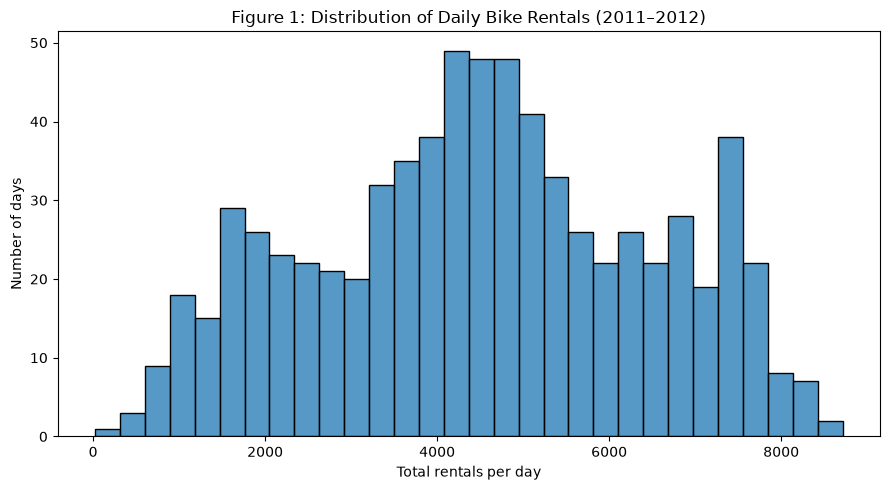

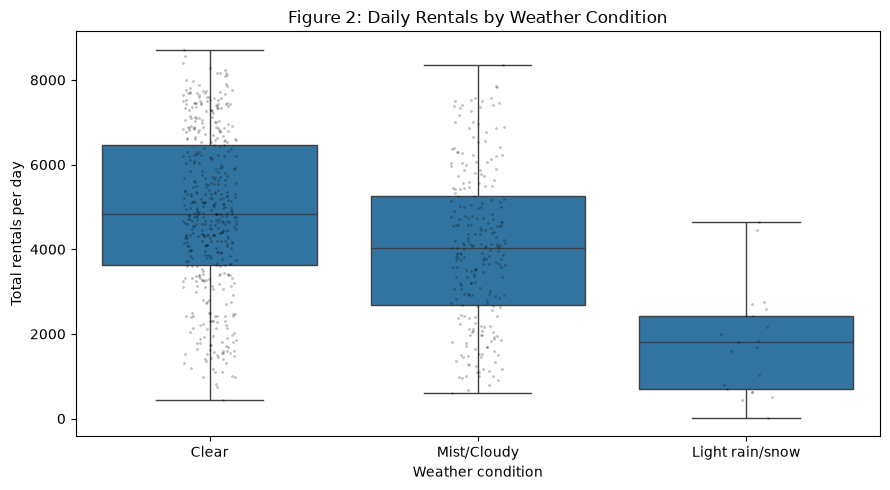

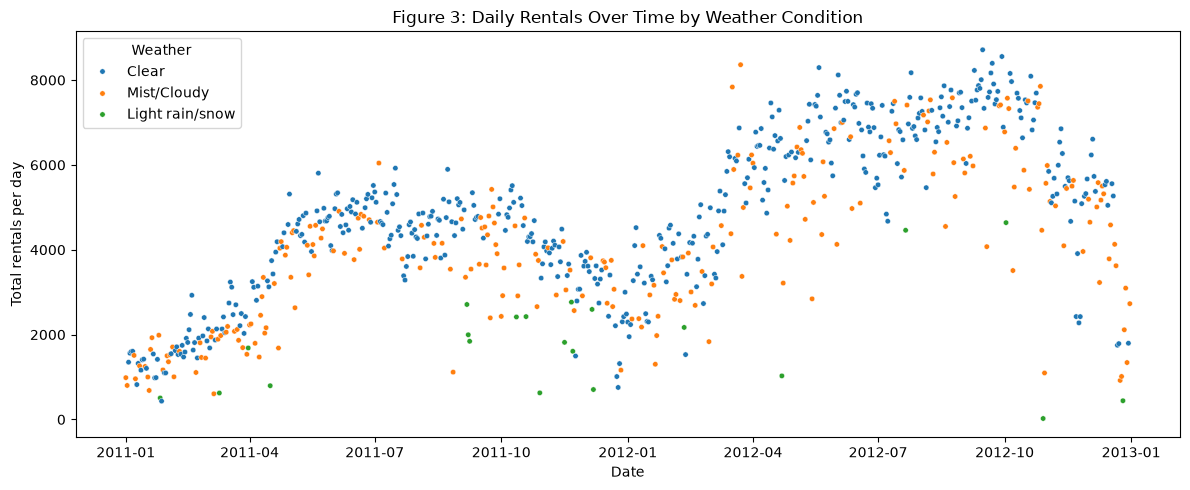

In [9]:
import os
os.makedirs("figures", exist_ok=True)
order = ["Clear", "Mist/Cloudy", "Light rain/snow"]

# Figure 1: overall distribution of daily rentals
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["cnt"], bins=30, ax=ax)
ax.set_title("Figure 1: Distribution of Daily Bike Rentals (2011–2012)")
ax.set_xlabel("Total rentals per day")
ax.set_ylabel("Number of days")
plt.tight_layout(); plt.savefig("figures/fig1_cnt_distribution.png", dpi=150); plt.show()

# Figure 2: rentals by weather condition
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="weather_label", y="cnt", order=order, ax=ax)
sns.stripplot(data=df, x="weather_label", y="cnt", order=order,
              color="black", alpha=0.25, size=2, ax=ax)
ax.set_title("Figure 2: Daily Rentals by Weather Condition")
ax.set_xlabel("Weather condition")
ax.set_ylabel("Total rentals per day")
plt.tight_layout(); plt.savefig("figures/fig2_cnt_by_weather.png", dpi=150); plt.show()

# Figure 3: rentals over time, coloured by weather
fig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(data=df, x="dteday", y="cnt", hue="weather_label",
                hue_order=order, s=15, ax=ax)
ax.set_title("Figure 3: Daily Rentals Over Time by Weather Condition")
ax.set_xlabel("Date")
ax.set_ylabel("Total rentals per day")
ax.legend(title="Weather")
plt.tight_layout(); plt.savefig("figures/fig3_cnt_over_time.png", dpi=150); plt.show()

In [10]:
# Figure 3 check: compare each light rain/snow day with the other days in the same two weeks
rain = df[df["weather_label"] == "Light rain/snow"]
rows = []
for _, r in rain.iterrows():
    nearby = df[(df["dteday"] - r["dteday"]).abs().dt.days.le(7)
                & (df["weather_label"] != "Light rain/snow")]
    rows.append({"date": r["dteday"].date(), "cnt": r["cnt"],
                 "nearby_median": nearby["cnt"].median()})
local = pd.DataFrame(rows)
local["ratio"] = (local["cnt"] / local["nearby_median"]).round(2)
print("Below the median of the surrounding ±7 days:",
      (local["cnt"] < local["nearby_median"]).sum(), "of", len(local))
print("Median ratio (rain day ÷ nearby median):", local["ratio"].median())
local

Below the median of the surrounding ±7 days: 21 of 21
Median ratio (rain day ÷ nearby median): 0.5


,date,cnt,nearby_median,ratio
0,2011-01-26,506,1388.0,0.36
1,2011-03-10,623,2051.0,0.30
2,2011-03-31,1685,2239.5,0.75
3,2011-04-16,795,3235.5,0.25
4,2011-09-06,2710,4851.5,0.56
5,2011-09-07,1996,4774.0,0.42
6,2011-09-08,1842,4745.0,0.39
7,2011-10-12,2416,4826.0,0.50
8,2011-10-19,2424,4308.0,0.56
9,2011-10-29,627,4010.0,0.16


### Comparing the visualizations

**Figure 1: shape of all daily rentals.** The distribution is wide (22 to 8,714) and has several peaks rather than one: a smaller bump around 1,500–2,000, the main peak around 4,000–5,000, and another around 7,300–7,500. This looks like several groups mixed together, which fits the data covering two years with very different demand (2011 mean 3,406, 2012 mean 5,600) and four seasons. So the pooled data isn't normal, but that doesn't by itself rule out a parametric test. What matters is the shape within each weather group, which I test in Section 5.

**Figure 2: rentals by weather.**
- *Medians:* 4,844 (Clear), 4,040 (Mist/Cloudy), 1,817 (Light rain/snow). Clear to Mist/Cloudy is a drop of about 800; Mist/Cloudy to Light rain/snow is a much bigger drop of about 2,200.
- *Overlap:* The Clear (3,636–6,458) and Mist/Cloudy (2,674–5,258) boxes overlap over most of their range. The Light rain/snow box (705–2,424) overlaps neither: its top is below the bottom of both other boxes.
- *Strip points:* Clear and Mist/Cloudy are dense clouds of 463 and 247 points; Light rain/snow is only 21 scattered points. Its box and median rest on very few days, and one day (22 rentals, Hurricane Sandy) sits on its own at the bottom.

**Figure 3: rentals over time.**
- *Short stretches:* In any stretch with a green point, it sits well below the blue and orange points from the same weeks. For example, 6–8 September 2011 had 1,842–2,710 rentals against about 4,750 on the surrounding days, and 22 April 2012 had 1,027 against about 6,270. The check above confirms this for every one of the 21 light rain/snow days: each is below the median of the other days within a week either side, and the typical one is about half (median ratio 0.50).
- *Overall pattern:* Rentals rise from winter lows to a summer–September peak and fall again each year, and every month of 2012 is higher than the same month of 2011. These two patterns move rentals by thousands of bikes a day, as much as the weather gap does.

**Which figure best supports the question?** Figure 2 compares the three groups directly and is the picture the Kruskal–Wallis test formalises. But I think **Figure 3** is the stronger evidence that weather itself matters. Most light rain/snow days are in 2011, the lower-demand year, so the gap in Figure 2 is partly a year effect. Figure 3 removes that problem by comparing each rain day with clear and cloudy days from the same weeks, when year and season are effectively held fixed, and the drop is still there every time. Figure 2 shows how big the gap is; Figure 3 shows that it isn't just a by-product of when the rainy days happened.

## 5. Hypothesis Test

In [11]:
groups = [df.loc[df["weather_label"] == w, "cnt"] for w in order]

# Normality within each group (Shapiro–Wilk)
for w, g in zip(order, groups):
    res = stats.shapiro(g)
    p_txt = "p < 0.0001" if res.pvalue < 0.0001 else f"p = {res.pvalue:.4f}"
    print(f"{w}: n={len(g)}, Shapiro W={res.statistic:.3f}, {p_txt}")

# Equal variances across groups (Levene, median-centred)
print(stats.levene(*groups, center="median"))

Clear: n=463, Shapiro W=0.976, p < 0.0001
Mist/Cloudy: n=247, Shapiro W=0.980, p = 0.0015
Light rain/snow: n=21, Shapiro W=0.921, p = 0.0923
LeveneResult(statistic=np.float64(2.967546907330999), pvalue=np.float64(0.052051813640993524))


### Choice of test

- **Normality:** Shapiro–Wilk rejects normality for Clear (p < 0.0001) and Mist/Cloudy (p = 0.0015). With hundreds of days in these groups, normality tests can flag even small departures (Ghasemi & Zahediasl, 2012). Light rain/snow passes (p = 0.092), but with only 21 days the test has little power to reject, so passing tells me little (Ghasemi & Zahediasl, 2012).
- **Equal variances:** Levene's test gives p = 0.052. This is a borderline result, not clear evidence either way, and it shouldn't be read very differently from p = 0.049 (Greenland et al., 2016). Together with the similar box heights in Figure 2, I treat the spreads as similar.

Normality fails for the two largest groups, so I use the **Kruskal–Wallis test** (Kruskal & Wallis, 1952) instead of a one-way ANOVA. It compares ranks rather than means, so the hypotheses are about distributions:

- `H₀`: daily rentals follow the same distribution on clear, misty/cloudy and light rain/snow days.
- `H₁`: rentals tend to be higher or lower in at least one weather group.

The groups have similar spreads, so a significant result can be read as a difference in **medians**: 4,844 (Clear), 4,040 (Mist/Cloudy) and 1,817 (Light rain/snow). A p-value alone doesn't say how large or important a difference is, so I report an effect size alongside it (Greenland et al., 2016).

In [12]:
# Kruskal–Wallis test with effect size (ε²)
h, p = stats.kruskal(*groups)
n = sum(len(g) for g in groups)
epsilon_sq = h / (n - 1)
print(f"Kruskal–Wallis H = {h:.2f}, df = {len(groups) - 1}, p = {p:.2e}, ε² = {epsilon_sq:.3f}")

Kruskal–Wallis H = 67.18, df = 2, p = 2.59e-15, ε² = 0.092


In [13]:
# Within-year check: does the weather difference hold inside each year?
for y in [2011, 2012]:
    sub = df[df["year"] == y]
    g_y = [sub.loc[sub["weather_label"] == w, "cnt"] for w in order]
    h_y, p_y = stats.kruskal(*g_y)
    eps_y = h_y / (sum(len(g) for g in g_y) - 1)
    medians = ", ".join(f"{w} {g.median():,.0f} (n={len(g)})" for w, g in zip(order, g_y))
    print(f"{y}: H = {h_y:.2f}, p = {p_y:.2e}, ε² = {eps_y:.3f} | medians: {medians}")

2011: H = 39.37, p = 2.83e-09, ε² = 0.108 | medians: Clear 4,104 (n=226), Mist/Cloudy 3,380 (n=124), Light rain/snow 1,817 (n=15)
2012: H = 39.75, p = 2.34e-09, ε² = 0.109 | medians: Clear 6,398 (n=237), Mist/Cloudy 5,191 (n=123), Light rain/snow 1,598 (n=6)


### Result

**Kruskal–Wallis H = 67.18, df = 2, p = 2.6 × 10⁻¹⁵, ε² = 0.092.**

- **Decision:** p is far below 0.05, so I reject H₀. Daily rentals are not distributed the same way across the three weather groups. With similar spreads, this means the medians differ: 4,844 (Clear), 4,040 (Mist/Cloudy) and 1,817 (Light rain/snow).
- **Effect size:** ε² = 0.092, so weather group accounts for about 9% of the variation in the ranks of daily rentals. The effect is real but explains only a small share of the day-to-day variation; the year and seasonal patterns in Figure 3 account for much more. The tiny p-value reflects the large sample (731 days) as much as the size of the effect, which is why the effect size is reported alongside it (Greenland et al., 2016).
- **Within each year:** the result holds in 2011 (H = 39.37, p = 2.8 × 10⁻⁹, ε² = 0.108) and in 2012 (H = 39.75, p = 2.3 × 10⁻⁹, ε² = 0.109). The effect is slightly larger within a year than pooled, because the jump between years no longer adds noise. The weather gap is therefore not just a by-product of most light rain/snow days falling in 2011. The 2012 light rain/snow group has only 6 days, so that median (1,598) is uncertain.
- **What the test doesn't show:** which pairs of groups differ. Figure 2 suggests light rain/snow is the group that stands apart, but I haven't run a post-hoc test. It also doesn't establish that weather *causes* the drop, since season and autocorrelation between days aren't controlled.

## 6. Summary

I explored whether daily Capital Bikeshare rentals in 2011–2012 differ across three weather conditions, using 731 days from the UCI Bike Sharing dataset. Screening the data turned up three issues: the Readme's season labels were shifted by one season (the codes follow astronomical seasons, so code 1 is winter), one day had an impossible humidity of 0, and the lowest-rental day (22 bikes) was Hurricane Sandy, which I kept as a real extreme-weather day. Because normality failed for the two largest groups, I used a Kruskal–Wallis test, which found a clear difference (H = 67.18, p = 2.6 × 10⁻¹⁵), with median rentals falling from 4,844 on clear days to 1,817 on light rain/snow days. The effect size was modest (ε² = 0.092), but the gap held within each year and on every one of the 21 light rain/snow days, each of which was below the median of the clear and cloudy days in the surrounding two weeks. The main challenges were confounding (most light rain/snow days fall in 2011, the lower-demand year), the small light rain/snow group, the lack of independence between consecutive days, and a weather coding so coarse that a hurricane counts as "light rain/snow".

## References

Blake, E. S., Kimberlain, T. B., Berg, R. J., Cangialosi, J. P., & Beven, J. L., II. (2013, February 12). *Tropical cyclone report: Hurricane Sandy (AL182012), 22–29 October 2012*. National Hurricane Center. https://www.nhc.noaa.gov/data/tcr/AL182012_Sandy.pdf

Fanaee-T, H. (2013). *Bike sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

Ghasemi, A., & Zahediasl, S. (2012). Normality tests for statistical analysis: A guide for non-statisticians. *International Journal of Endocrinology and Metabolism, 10*(2), 486–489. https://doi.org/10.5812/ijem.3505

Greenland, S., Senn, S. J., Rothman, K. J., Carlin, J. B., Poole, C., Goodman, S. N., & Altman, D. G. (2016). Statistical tests, P values, confidence intervals, and power: A guide to misinterpretations. *European Journal of Epidemiology, 31*, 337–350. https://doi.org/10.1007/s10654-016-0149-3

Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441

Lusa, L., Proust-Lima, C., Schmidt, C. O., Lee, K. J., le Cessie, S., Baillie, M., Lawrence, F., & Huebner, M. (2024). Initial data analysis for longitudinal studies to build a solid foundation for reproducible analysis. *PLOS ONE, 19*(5), e0295726. https://doi.org/10.1371/journal.pone.0295726